# Supplementary Figure S13b. Number of snRNA-seq cell types per AD locus (secondary meta-analysis)

Colocalization CoS of the secondary AD GWAS analysis (130 CoS) are mapped to unified AD loci (`AD_loci_unified_cs95orColocs_Pval1e5_variant_level.csv.gz`; CoS without a matching locus keep their own region as locus). For each AD locus with *cis*-eQTL (top) or *trans*-eQTL (*trans*-eGene / eProgram / global program; bottom) colocalization, the number of distinct snRNA-seq cell types involved is counted (6 to 0; 0 = bulk contexts only). Counts only.

Integrity note: the V1 panel (and the stored `Figure5b_celltype_count_barplot_summary.tsv`) includes the author's injected fake signal row, which added 2 *cis* loci (56 vs 54 clean, both with 0 cell types since the fake *cis* outcome was labelled PCC) and 2 *trans* loci (55 vs 53 clean, both with 1 cell type, Exc). The fake row is removed here.

Input: `data/Figure_S13b_n_celltypes_per_locus.rds`.

In [1]:
suppressPackageStartupMessages(library(ggplot2))
d <- readRDS("data/Figure_S13b_n_celltypes_per_locus.rds")
d

category,n_celltypes,n_loci,total,locus_unit
<fct>,<int>,<int>,<int>,<chr>
cis-eQTL,6,0,54,unified AD locus
cis-eQTL,5,2,54,unified AD locus
cis-eQTL,4,1,54,unified AD locus
cis-eQTL,3,5,54,unified AD locus
cis-eQTL,2,13,54,unified AD locus
cis-eQTL,1,20,54,unified AD locus
cis-eQTL,0,13,54,unified AD locus
trans-eQTL,6,1,53,unified AD locus
trans-eQTL,5,8,53,unified AD locus


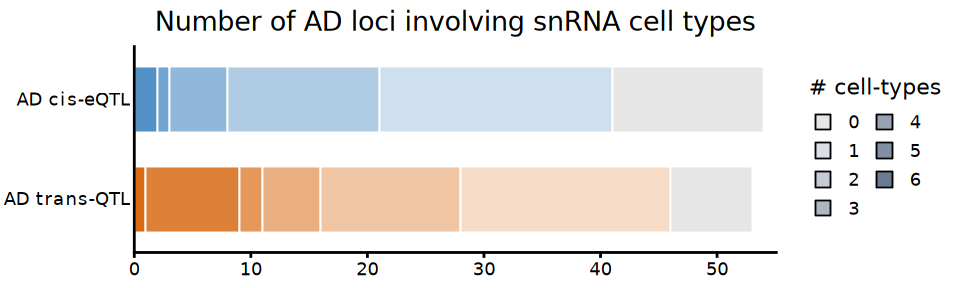

In [2]:
cat_colors <- c("cis-eQTL" = "#2171B5", "trans-eQTL" = "#D55E00")
y_labels <- c(expression(AD ~ italic(cis) * "-eQTL"), expression(AD ~ italic(trans) * "-QTL"))
blend_with_white <- function(hex, w) {
  rgb <- grDevices::col2rgb(hex) / 255
  out <- rgb * (1 - w) + w
  grDevices::rgb(out[1], out[2], out[3])
}
white_weights <- c("1" = 0.78, "2" = 0.64, "3" = 0.50, "4" = 0.36, "5" = 0.22, "6" = 0.08)
d <- d[order(d$category, -d$n_celltypes), ]
d$xmax <- ave(d$n_loci, d$category, FUN = cumsum)
d$xmin <- d$xmax - d$n_loci
d$y <- as.numeric(factor(d$category, levels = rev(levels(d$category))))
d$fill <- mapply(function(cat, n) if (n == 0) "#E6E6E6" else blend_with_white(cat_colors[[cat]], white_weights[[as.character(n)]]),
                 as.character(d$category), d$n_celltypes)
legend_df <- data.frame(n_celltypes = factor(0:6),
                        fill = c("#E6E6E6", sapply(1:6, function(n) blend_with_white("#5D6F88", white_weights[[as.character(n)]]))))
p <- ggplot(d[d$n_loci > 0, ]) +
  geom_rect(aes(xmin = xmin, xmax = xmax, ymin = y - 0.33, ymax = y + 0.33), fill = d$fill[d$n_loci > 0],
            color = "white", linewidth = 0.4) +
  geom_point(data = legend_df, aes(x = 0, y = 1, fill = n_celltypes), shape = 22, size = 0, alpha = 0) +
  scale_fill_manual(values = setNames(legend_df$fill, legend_df$n_celltypes), name = "# cell-types") +
  guides(fill = guide_legend(ncol = 2, override.aes = list(size = 4.5, alpha = 1))) +
  scale_y_continuous(breaks = seq_along(levels(d$category)), labels = rev(y_labels), expand = expansion(add = 0.2)) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.02))) +
  labs(x = NULL, y = NULL, title = "Number of AD loci involving snRNA cell types") +
  theme_classic(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5), axis.ticks.y = element_blank())

options(repr.plot.width = 8, repr.plot.height = 2.4)
p